In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from tqdm import tqdm
import sys
import os
import mdtraj as md

sys.path.append('..')
from src import visualisation as vis

## PRM-SH3 Single-chain single-repeat Test Run

In [3]:
# Loading trajectory
pdb_path = "/home/fknudsen/calvados-slim/data/test/slabC3_COM_LJcutoff2.0Gocutoff2.0_GoTrueGo_basic_2.45epsilon_GopairsCutoff0.95_box707070_1/PRM1_SH31_1_1/traj_centered.pdb"
dcd_path = "/home/fknudsen/calvados-slim/data/test/slabC3_COM_LJcutoff2.0Gocutoff2.0_GoTrueGo_basic_2.45epsilon_GopairsCutoff0.95_box707070_1/PRM1_SH31_1_1/traj_centered.dcd"

traj = md.load(dcd_path, top=pdb_path)
n_frames = len(traj)
total_time = (n_frames//4000) * 45000 # ns
dt = total_time/n_frames
time = np.arange(0,total_time, step=dt)

In [4]:
# Specifying chains
prm_indices = traj.topology.select('chainid 0')
sh3_indices = traj.topology.select('chainid 1')

# Specifying pairs
pair_indices = np.array(np.meshgrid(prm_indices, sh3_indices)).T.reshape(-1, 2)

# Loading SLiM GO pairs
slim_pair_indices = np.load('../data/test/slabC3_COM_LJcutoff2.0Gocutoff2.0_GoTrueGo_basic_2.45epsilon_GopairsCutoff0.95_box707070_1/PRM1_SH31_1_1/0/Go_pairs_list.npy')

In [5]:
# Calculating concentration
box_volume = traj.unitcell_volumes[0] * 1e-24 # L
N_A = 6.02e23
chains = 1
chain_concentration = 1e6 * (chains) / (N_A * box_volume) # µM

# Defining Kd estimation
@np.vectorize
def calc_Kd(fraction_bound, concentration):
    fc = fraction_bound
    Pt = concentration
    Lt = Pt
    if fc == 0.0 or fc == 1.0:
        return np.nan
    Kd = Pt * fc + Lt / fc - Pt - Lt
    return Kd

In [6]:
# Minimum distance
pair_dists = md.compute_distances(traj, pair_indices, periodic=True) * 10.0 # Å
min_dists = pair_dists.min(axis=1)

# COG distance
cogs_prm = np.mean(traj.xyz[:, prm_indices, :], axis=1) * 10.0 # Å
cogs_sh3 = np.mean(traj.xyz[:, sh3_indices, :], axis=1) * 10.0 # Å
cog_dists = np.linalg.norm(cogs_prm - cogs_sh3, axis=1)

# SLiM contacts
contact_cutoff = 9.5 # Å
bound_cutoff = 0.05 # Fraction of contacts
slim_dists = md.compute_distances(traj, slim_pair_indices, periodic=True) * 10.0 # Å
slim_contacts = slim_dists <= contact_cutoff
bound_frames = slim_contacts.mean(axis=1) > bound_cutoff
transitions = bound_frames[:-1] != bound_frames[1:]
fraction_bound = bound_frames.mean()
Kd = calc_Kd(fraction_bound, chain_concentration)
print(f"{Kd=:.2f}µM")

Kd=279.53µM


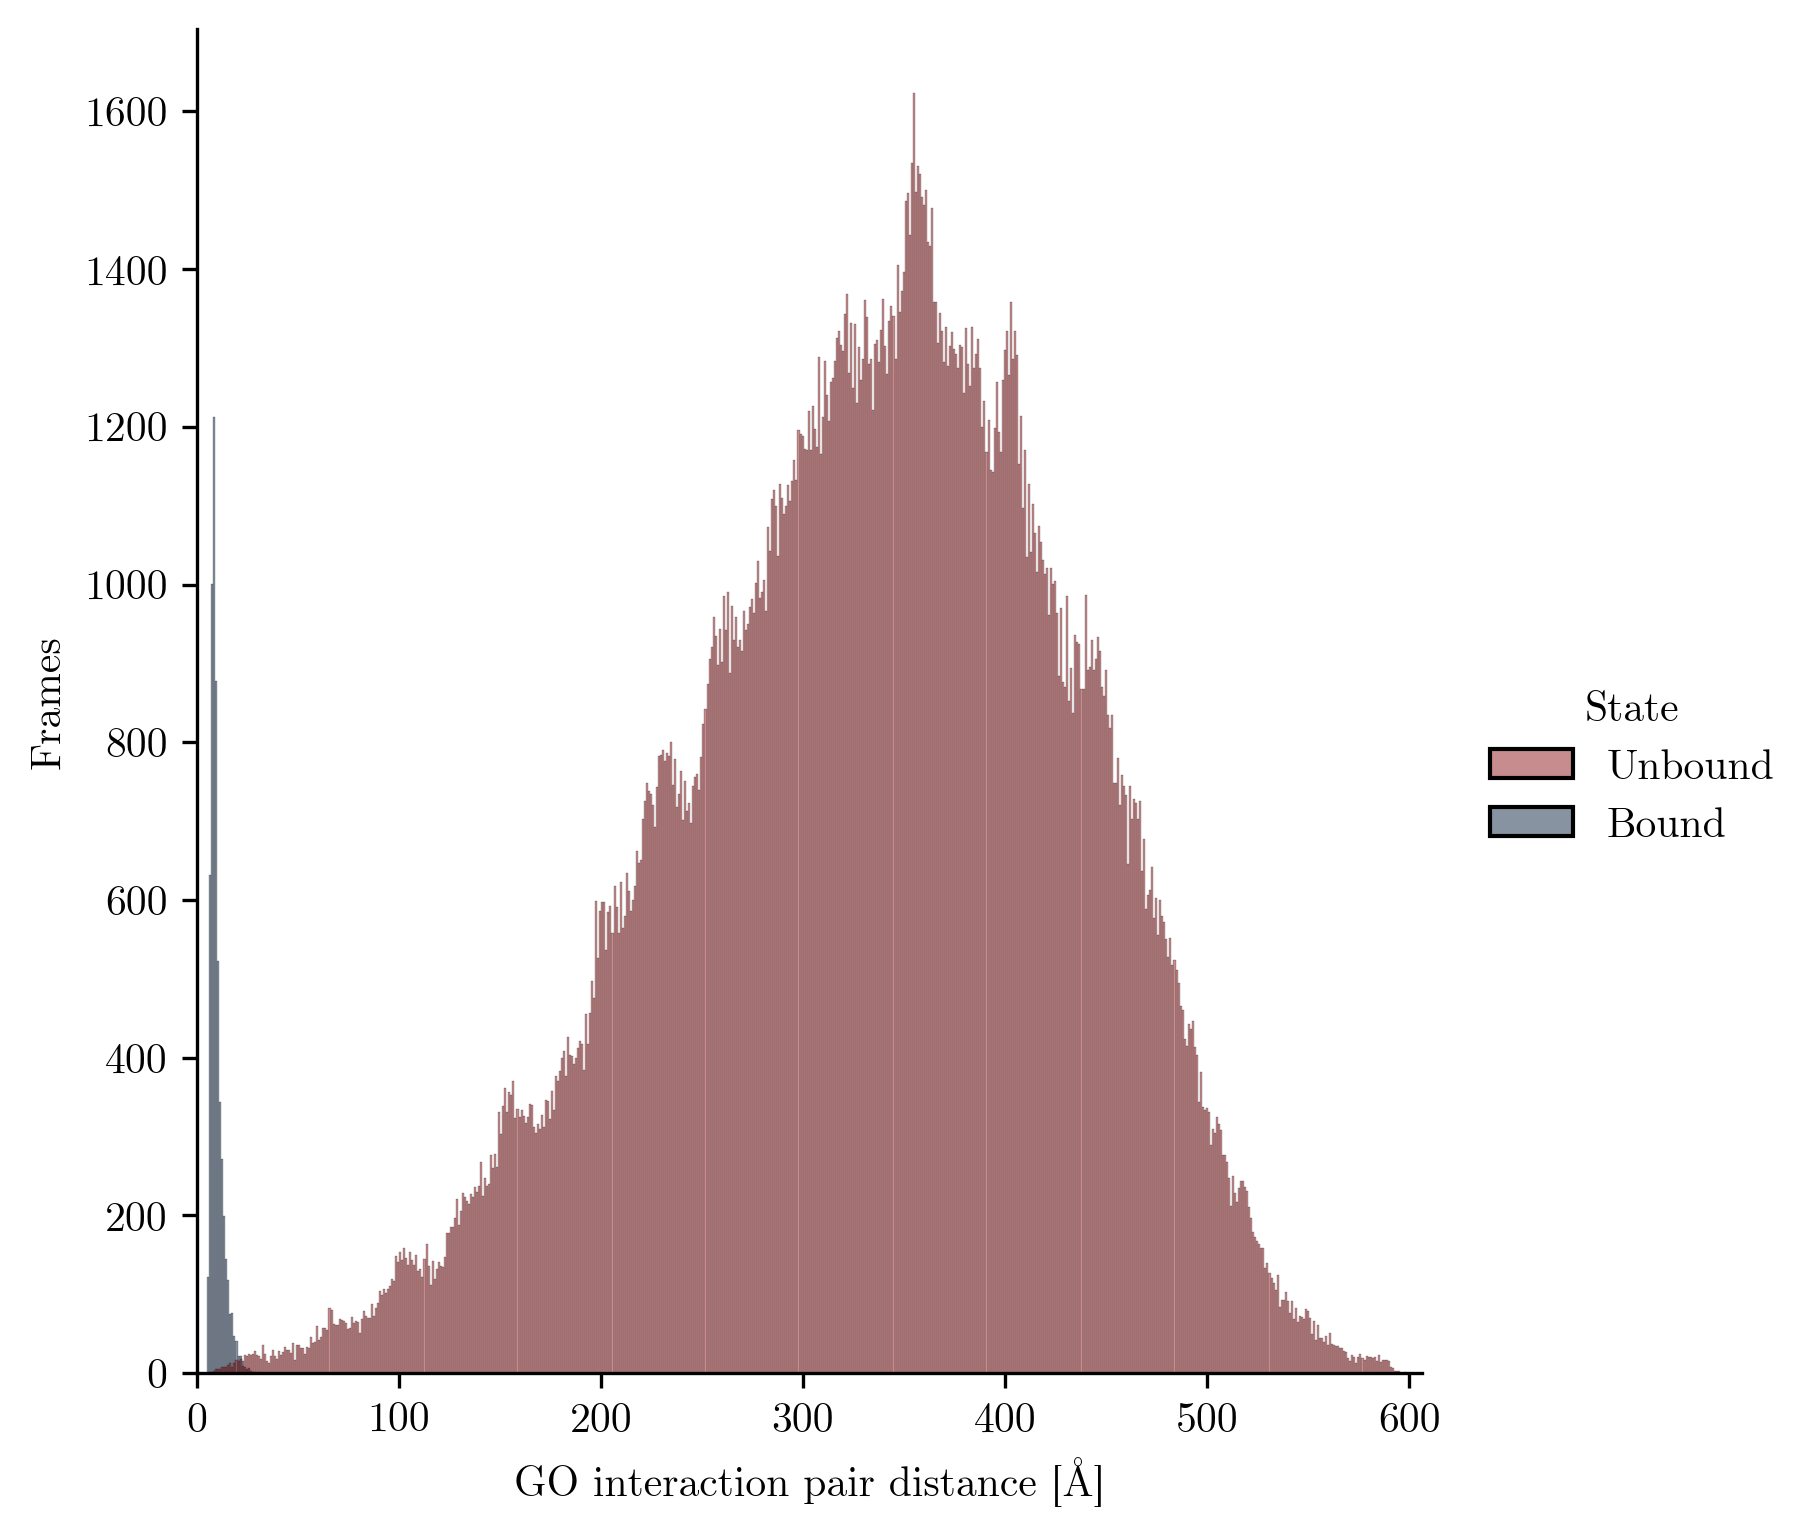

Text(25.074430555555498, 0.5, 'Frames')

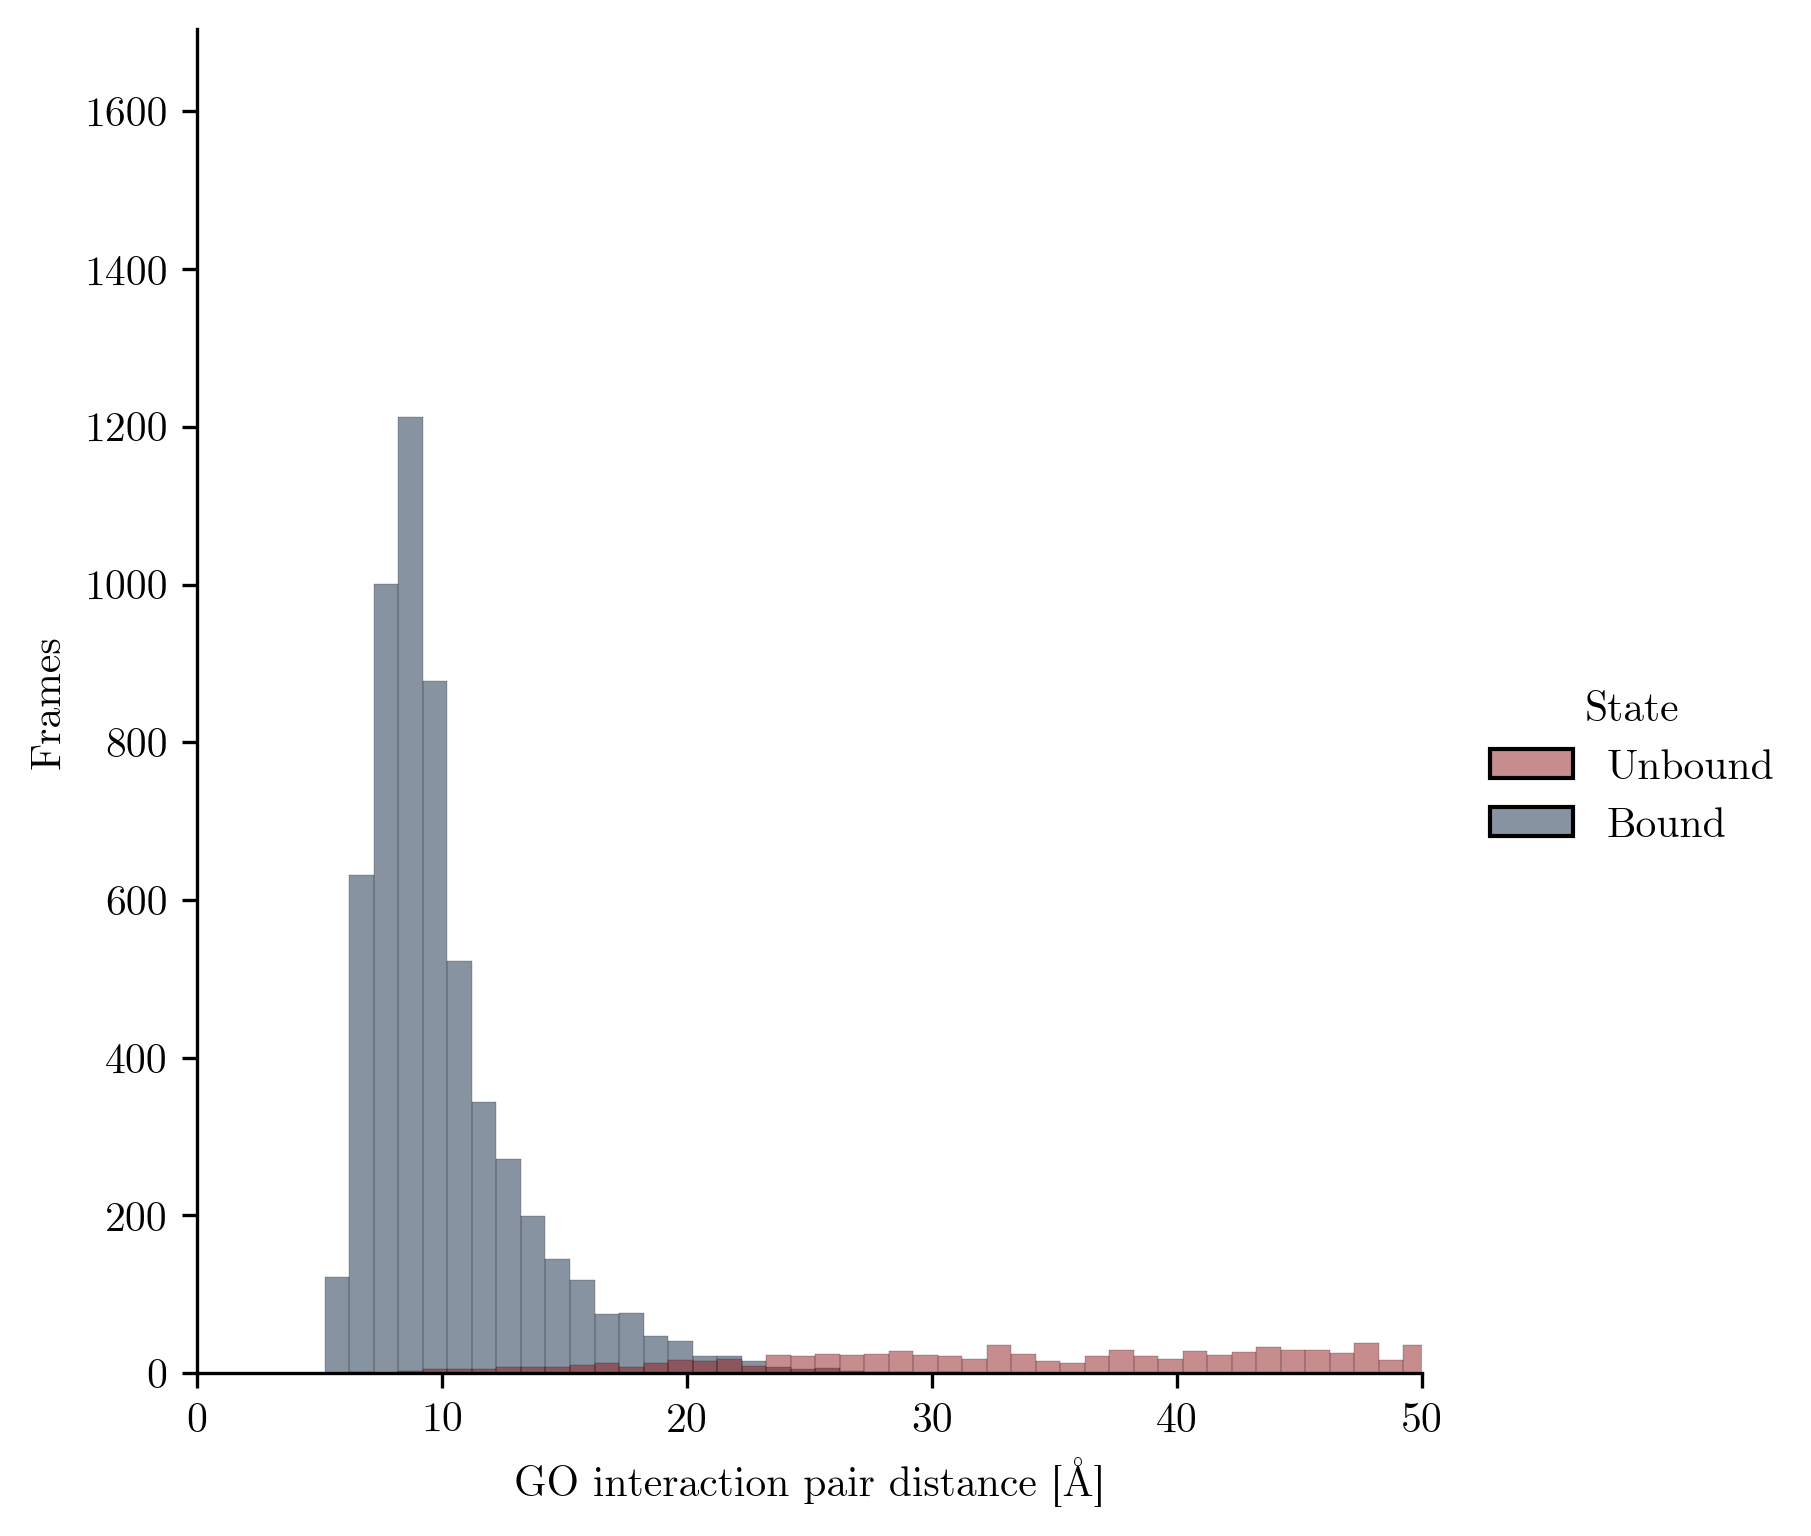

In [7]:
# Distribution of interaction term distances
sns.displot(
    x=slim_dists.flatten(),
    binwidth=1,
    hue=pd.Series(np.repeat(bound_frames, slim_dists.shape[1]), name="State").map({True:'Bound', False:'Unbound'}),
)
plt.xlim(0,700*np.sqrt(3)/2)
plt.xlabel("GO interaction pair distance [Å]")
plt.ylabel("Frames")
plt.show()

sns.displot(
    x=slim_dists.flatten(),
    binwidth=1,
    hue=pd.Series(np.repeat(bound_frames, slim_dists.shape[1]), name="State").map({True:'Bound', False:'Unbound'}),
)
plt.xlim(0,50)
plt.xlabel("GO interaction pair distance [Å]")
plt.ylabel("Frames")

Text(0.5, 1.0, 'Convergence of 1-repeat PRM-SH3 $K_d$')

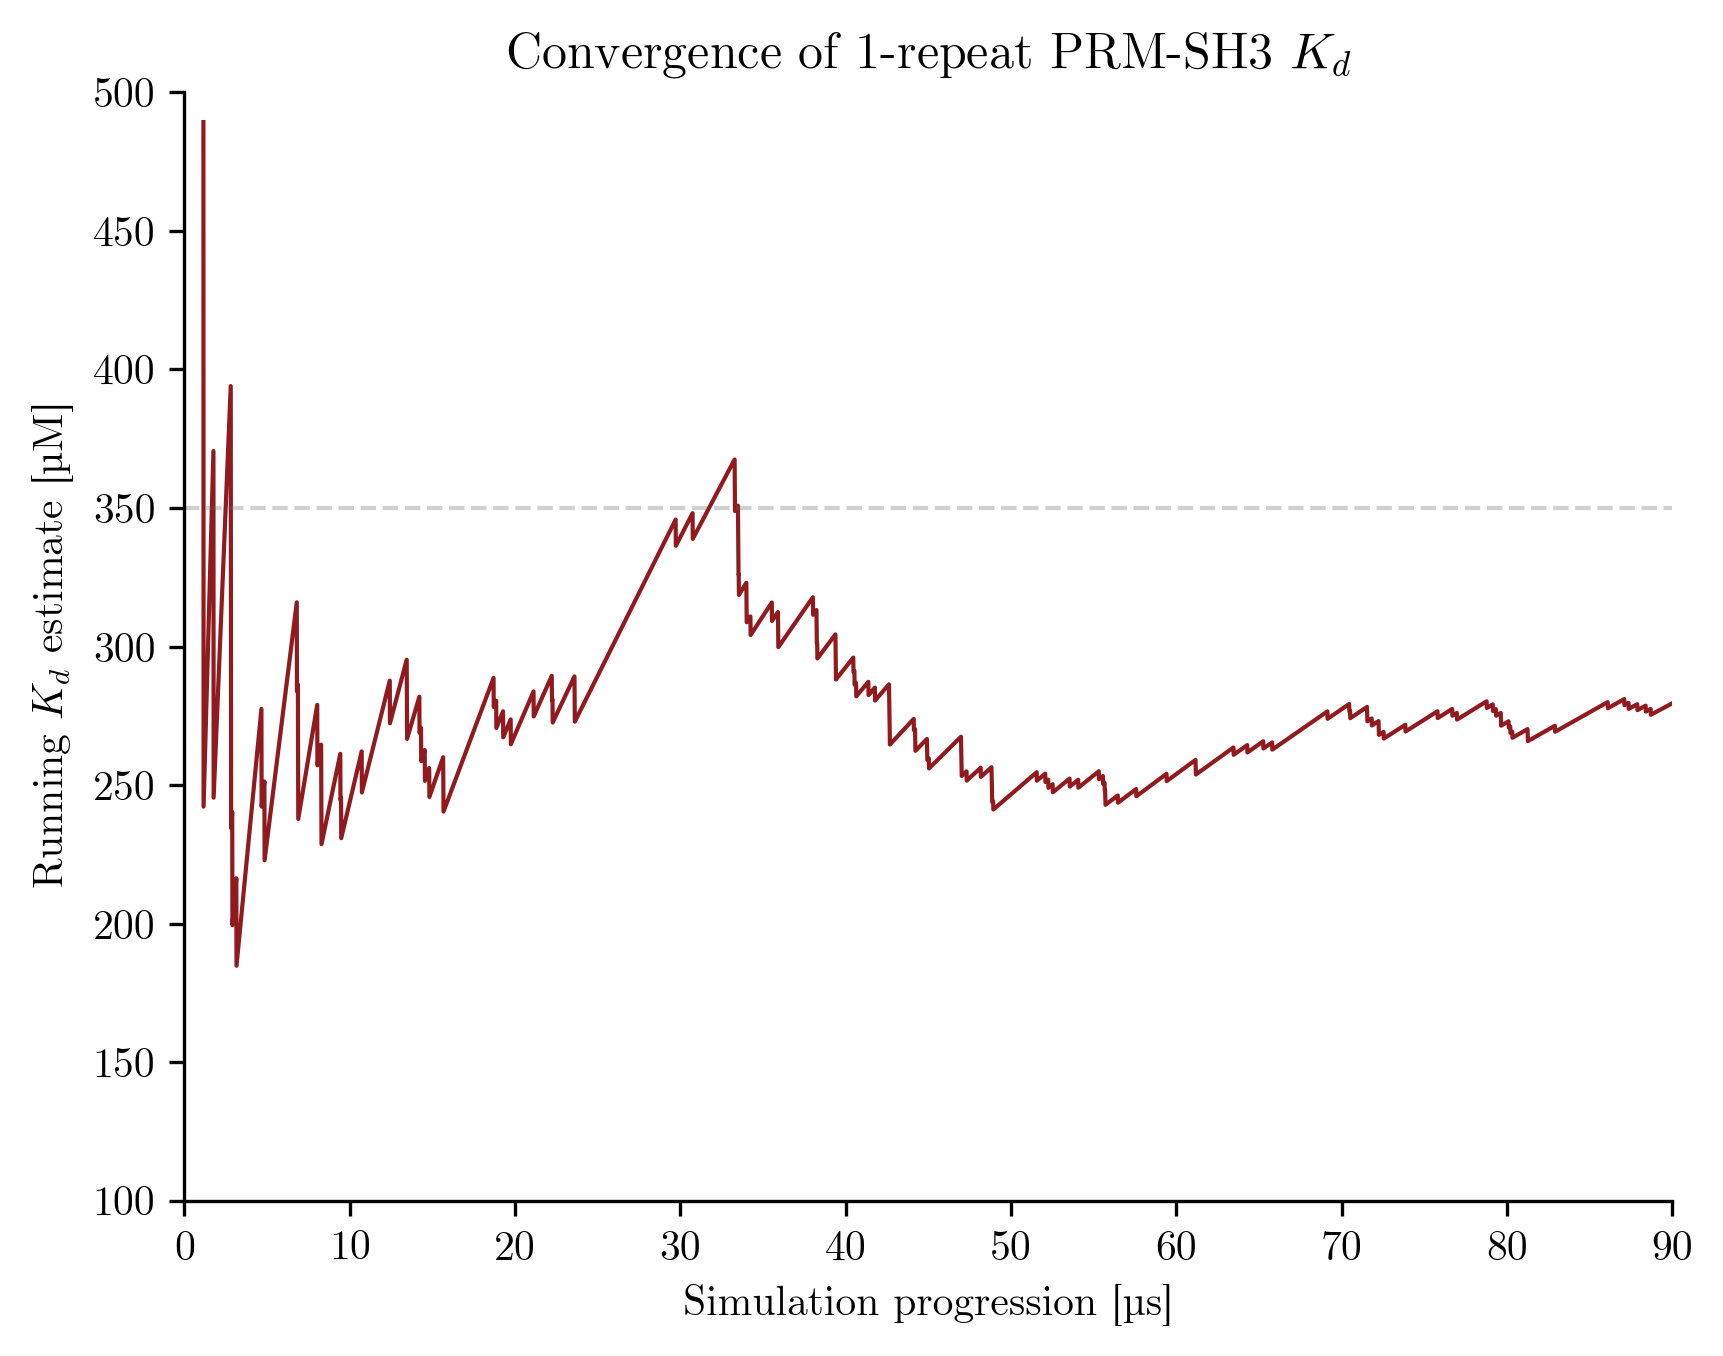

In [8]:
# Convergence of Kd
fraction_bound_convergence = bound_frames.cumsum() / np.ones(bound_frames.shape[0]).cumsum()
Kd_convergence = calc_Kd(fraction_bound_convergence, chain_concentration)

plt.plot(time*1e-3, Kd_convergence, linewidth=1)
plt.xlim(0, total_time*1e-3)
plt.ylim(100,500)
plt.xlabel("Simulation progression [µs]")
plt.ylabel("Running $K_d$ estimate [µM]")
plt.hlines(350, *plt.xlim(), color=vis.gray, alpha=0.3, linestyles='dashed', linewidth=1)
plt.title("Convergence of 1-repeat PRM-SH3 $K_d$")

Text(0.5, 1.0, 'Convergence of 1-repeat PRM-SH3 $K_d$')

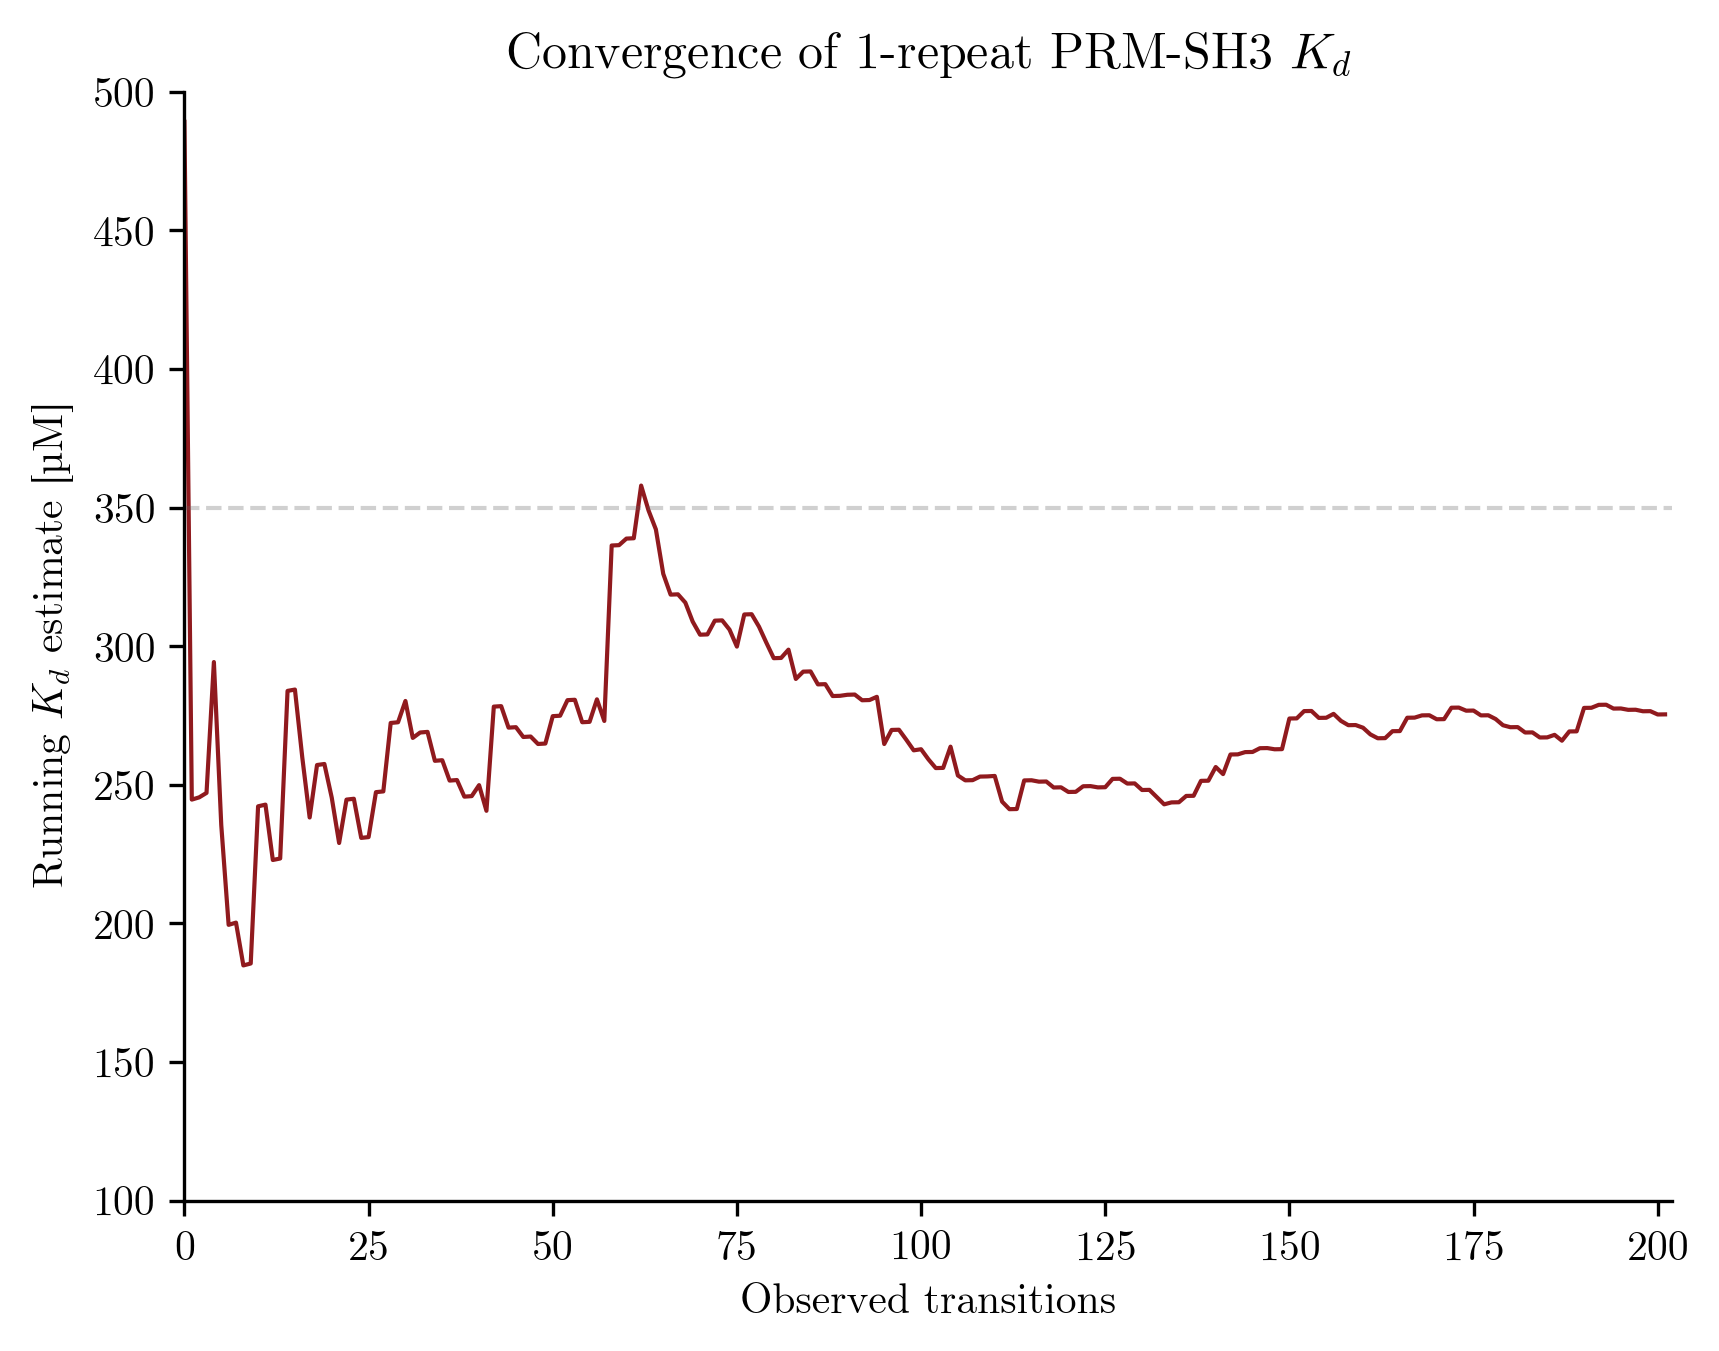

In [9]:
plt.plot(Kd_convergence[1:][transitions])
plt.xlim(0,transitions.sum())
plt.ylim(100,500)
plt.xlabel("Observed transitions")
plt.ylabel("Running $K_d$ estimate [µM]")
plt.hlines(350, *plt.xlim(), color=vis.gray, alpha=0.3, linestyles='dashed', linewidth=1)
plt.title("Convergence of 1-repeat PRM-SH3 $K_d$")

Text(0, 0.5, 'Observed transitions')

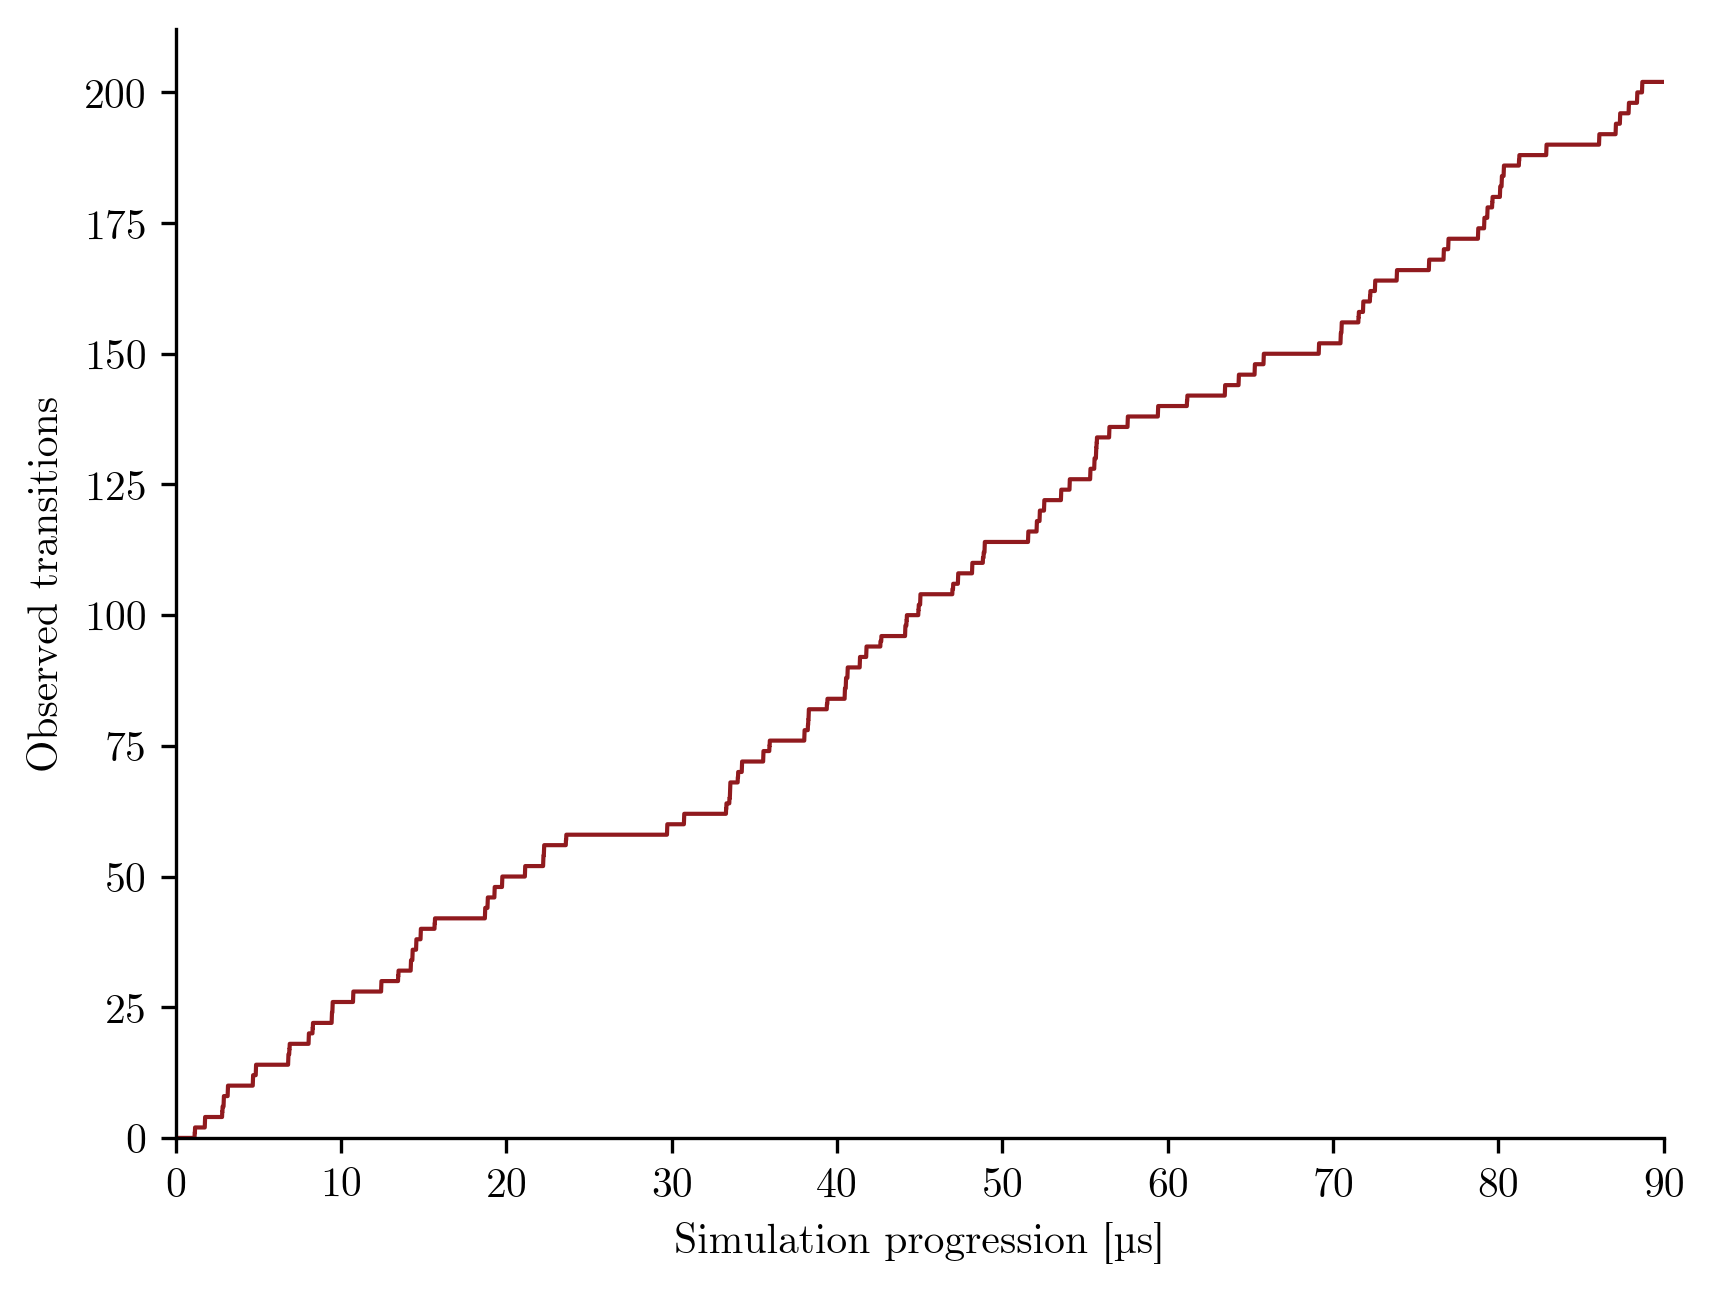

In [10]:
plt.plot(time[1:]*1e-3, transitions.cumsum(), linewidth=1)
plt.xlim(0, total_time*1e-3)
plt.ylim(0)
plt.xlabel("Simulation progression [µs]")
plt.ylabel("Observed transitions")

(0.0, 1.0)

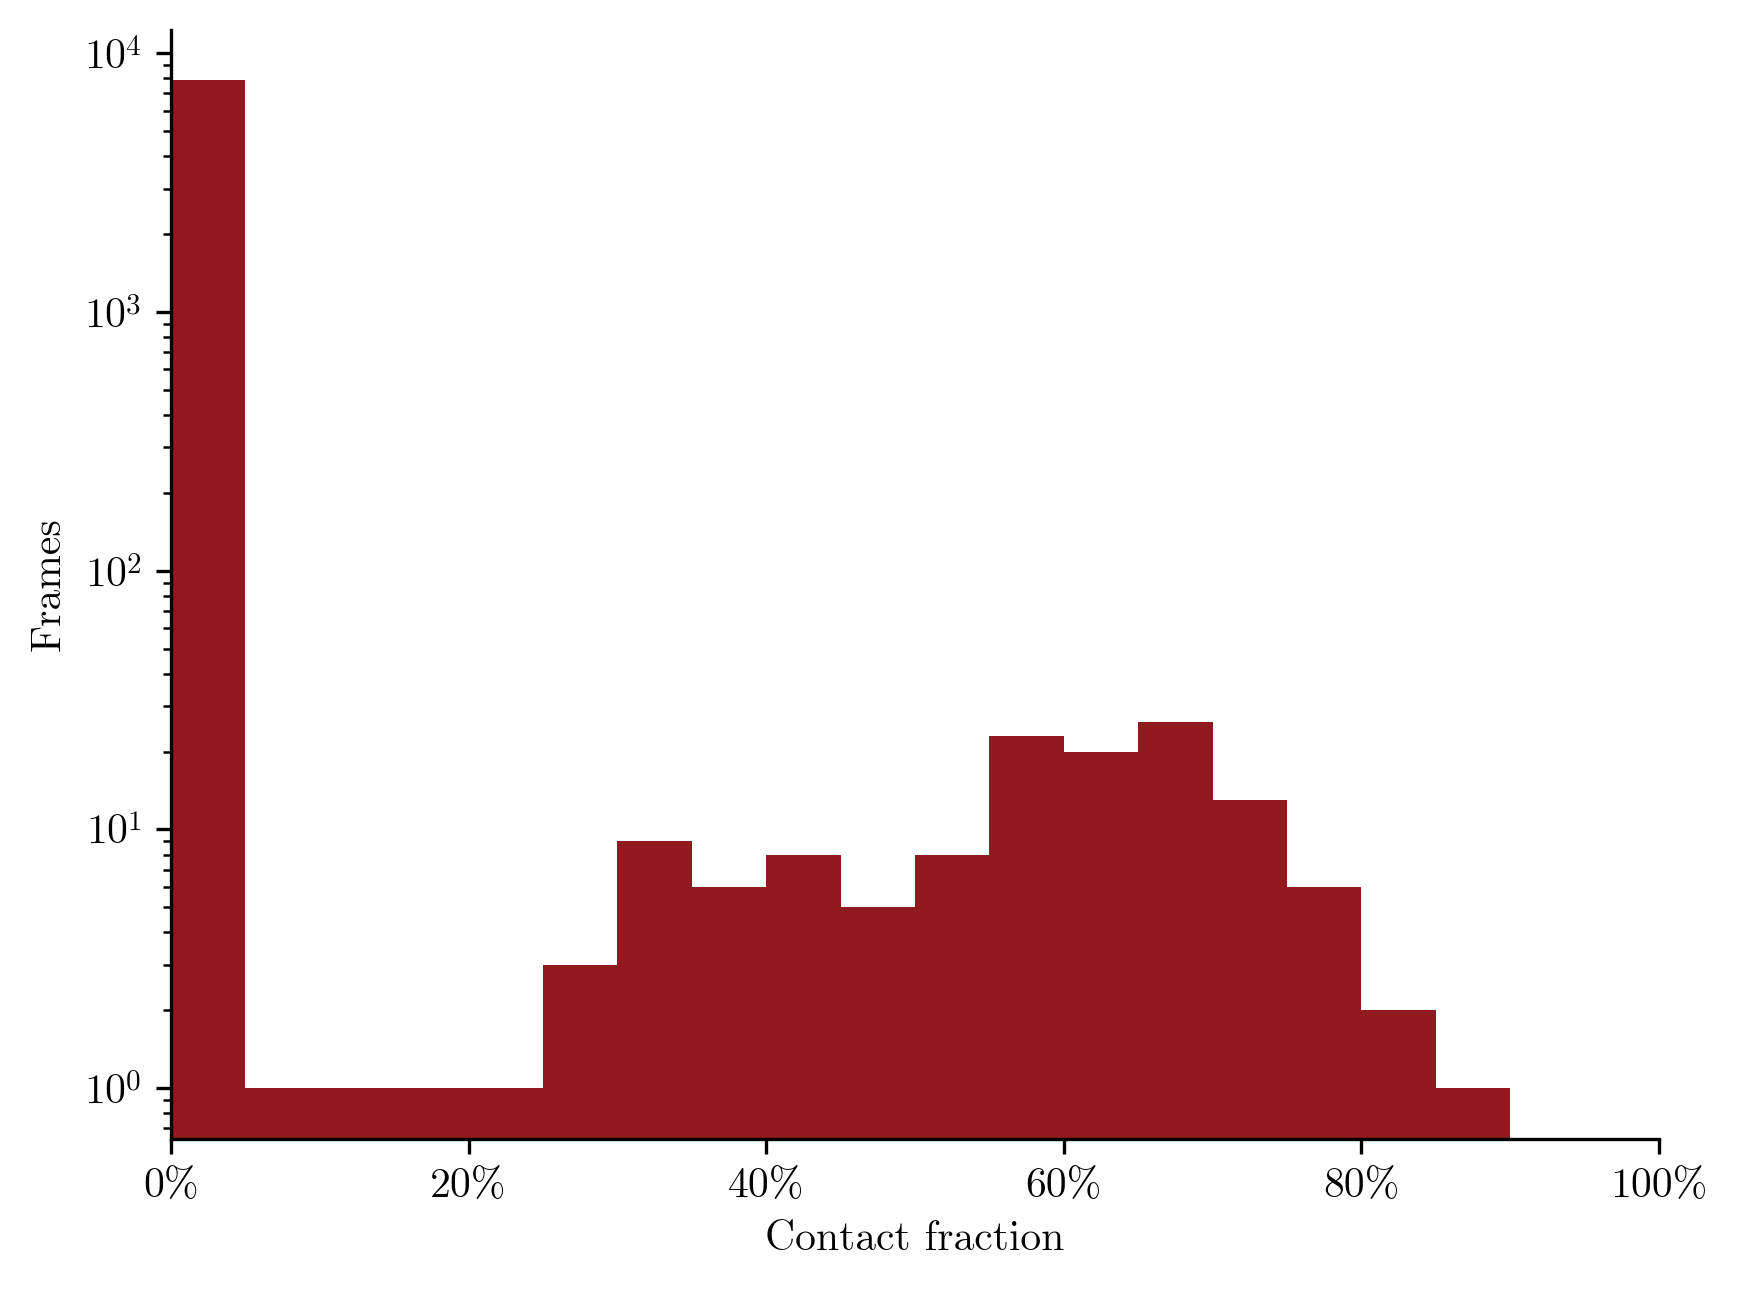

In [11]:
plt.hist(slim_contacts.mean(axis=1), bins=np.arange(0,1,0.05))
plt.yscale('log')
vis.percent_axis('x')
plt.xlabel("Contact fraction")
plt.ylabel("Frames")
plt.xlim(0,1)

(0.0, 90.0)

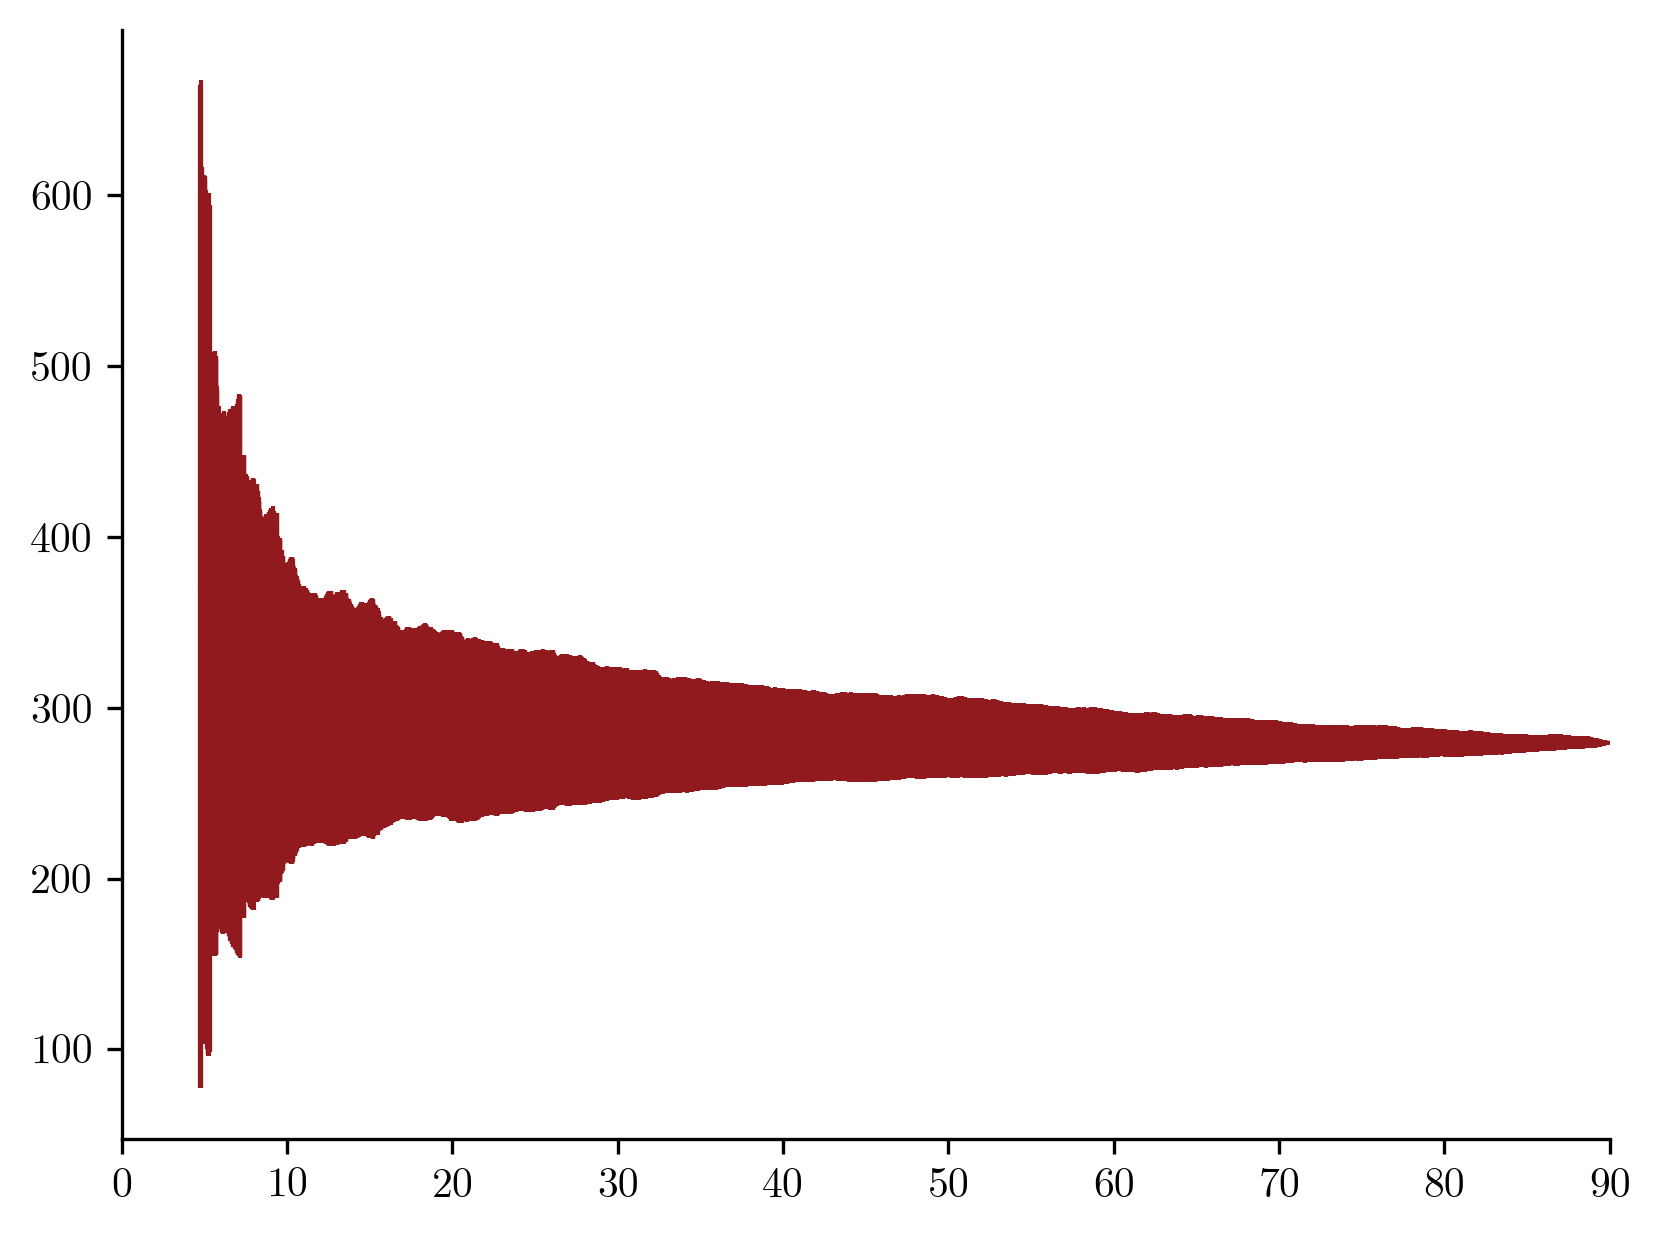

In [12]:
# Convergence under shuffling
shuffles = 100
Kd_convergence_shuffleds = []
bound_frames_shuffled = bound_frames.copy()
for _ in range(shuffles):
    np.random.shuffle(bound_frames_shuffled)
    fraction_bound_convergence_shuffled = bound_frames_shuffled.cumsum() / np.ones(bound_frames_shuffled.shape[0]).cumsum()
    Kd_convergence_shuffled = calc_Kd(fraction_bound_convergence_shuffled, chain_concentration)
    Kd_convergence_shuffleds.append(Kd_convergence_shuffled)
Kd_convergence_shuffleds = np.array(Kd_convergence_shuffleds).T

plt.errorbar(
    time*1e-3,
    Kd_convergence_shuffleds.mean(axis=1),
    Kd_convergence_shuffleds.std(axis=1)
)
plt.xlim(0, total_time*1e-3)


## PRM-SH3 Single-chain single-repeat Parameter Scan

In [13]:
sim_dirs = [d for d in os.listdir('../data/prm_sh3_scan') if d[:6] == 'slabC3']

sims = []
for sim_dir in tqdm(sim_dirs):

    if sim_dir[:6] != 'slabC3':
        continue
    
    # Reading parameters
    epsilon = float(sim_dir.split('epsilon')[0].split('_')[-1])
    cutoff = float(sim_dir.split('GopairsCutoff')[-1].split('_')[0])
    
    # Loading trajectory
    dcd_path = f"../data/prm_sh3_scan/{sim_dir}/PRM1_SH31_1_1/traj_centered.dcd"
    pdb_path = f"../data/prm_sh3_scan/{sim_dir}/PRM1_SH31_1_1/traj_centered.pdb"
    traj = md.load(dcd_path, top=pdb_path)

    # Loading SLiM GO pairs
    slim_pair_indices = np.load(f'../data/prm_sh3_scan/{sim_dir}/PRM1_SH31_1_1/0/Go_pairs_list.npy')

    # Calculating concentration
    box_volume = traj.unitcell_volumes[0] * 1e-24 # L
    N_A = 6.02e23
    chains = 1
    chain_concentration = 1e6 * (chains) / (N_A * box_volume) # µM

    # Defining Kd estimation
    @np.vectorize
    def calc_Kd(fraction_bound, concentration):
        fc = fraction_bound
        Pt = concentration
        Lt = Pt
        if fc == 0.0:
            return 0
        if fc == 1.0:
            return np.inf
        Kd = Pt * fc + Lt / fc - Pt - Lt
        return Kd

    # Time
    n_frames = len(traj)
    dt = 5000 * 10e-6 # ns, stride x timestep
    total_time = n_frames * dt
    time = np.arange(0,total_time, step=dt)

    # SLiM contacts
    contact_cutoff = cutoff*10 # Å
    bound_cutoff = 0.05 # Fraction of contacts
    slim_dists = md.compute_distances(traj, slim_pair_indices, periodic=True) * 10.0 # Å
    slim_contacts = slim_dists <= contact_cutoff

    # Transitions
    bound_frames = slim_contacts.mean(axis=1) > bound_cutoff
    transitions = bound_frames[1:] != bound_frames[:-1]
    transitions = np.concatenate([[False],transitions])

    # Kd
    fc = bound_frames.mean()
    Kd = calc_Kd(fc, chain_concentration)

    # Kd convergence
    fc_convergence = bound_frames.cumsum() / np.ones(bound_frames.shape[0]).cumsum()
    Kd_convergence = calc_Kd(fc_convergence, chain_concentration)

    sims.append({
        'time': time,
        'epsilon': epsilon,
        'cutoff': cutoff,
        'Kd': float(Kd),
        'fc': fc,
        'Kd_convergence': Kd_convergence,
        'transitions': transitions,
    })

sims = pd.DataFrame(sims)
sims.to_parquet('.temp/sims.parquet')

  0%|          | 0/25 [00:00<?, ?it/s]

100%|██████████| 25/25 [14:31<00:00, 34.85s/it]


Text(0.5, 0.98, 'Convergence of 1-repeat PRM-SH3 $K_d$')

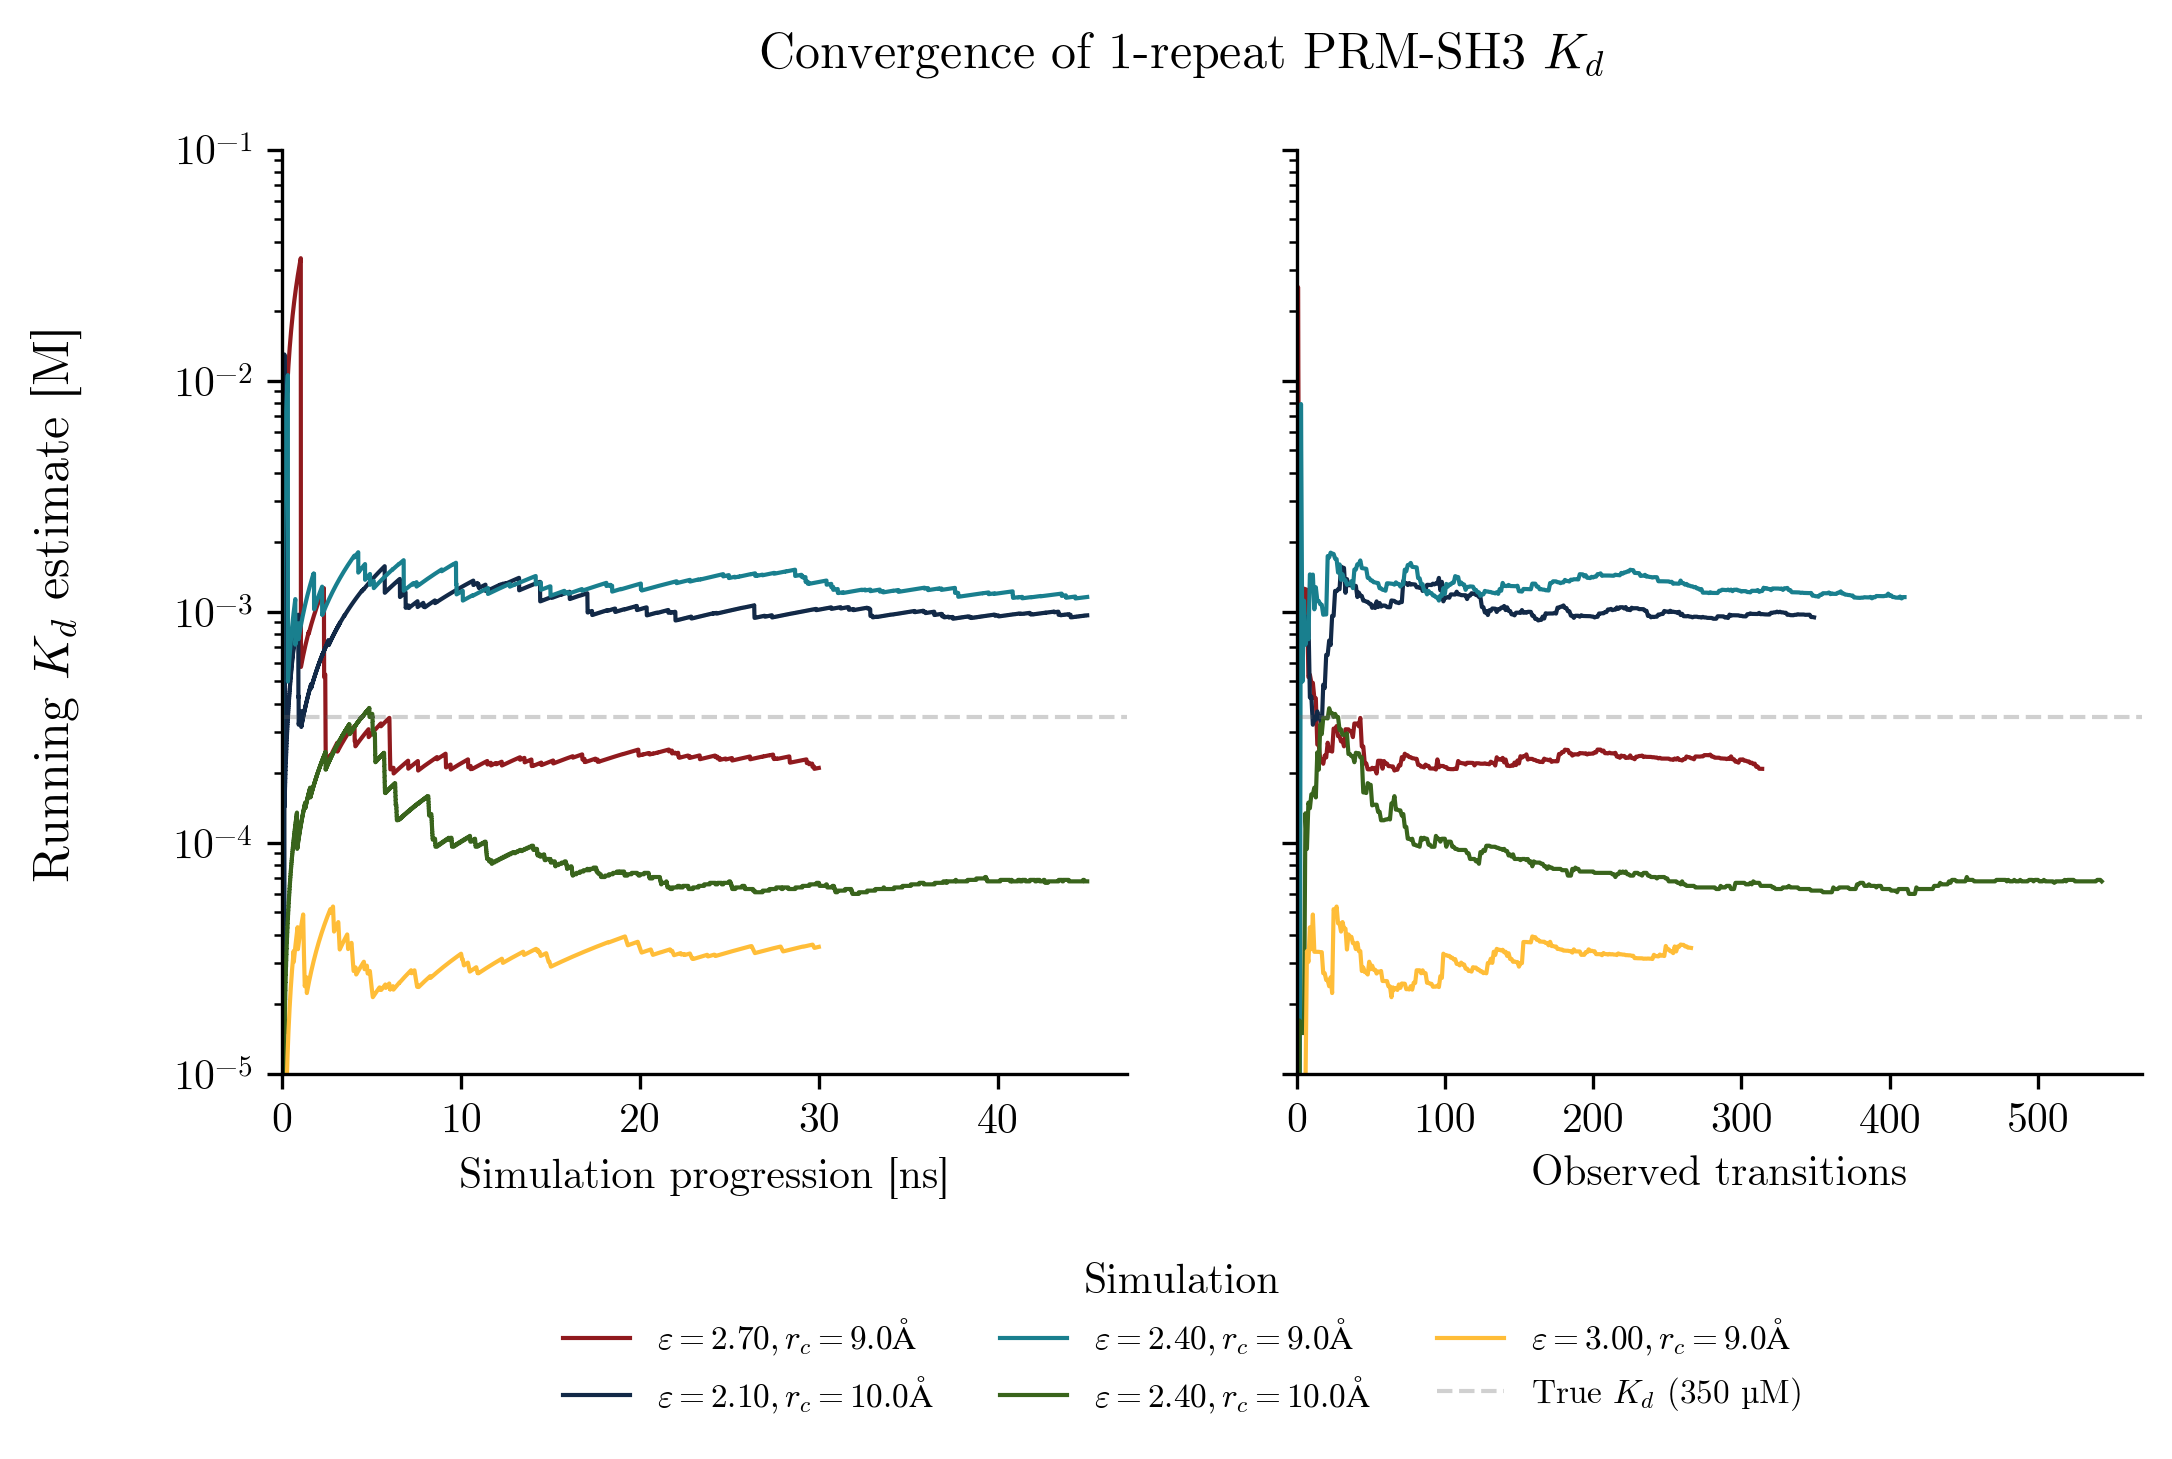

In [16]:
# Convergence between simulations
fig, axes = plt.subplots(1,2, sharey=True, figsize=(8,4))
true_Kd = 350
topn = 5

for sim_loc in (sims['Kd']/true_Kd).map(np.log10).abs().nsmallest(topn).index:
    sim = sims.loc[sim_loc]
    sim_label = r'$\varepsilon='+f'{sim["epsilon"]:.2f}' + r', r_c=' + f'{sim["cutoff"]*10:.1f}' +r'\text{Å}$'
    axes[0].plot(sim['time']*1e-3, sim['Kd_convergence']*1e-6, label=sim_label)
    axes[1].plot(sim['Kd_convergence'][sim['transitions']]*1e-6)

axes[0].set_xlim(0)
axes[0].set_yscale('log')
axes[0].set_ylim(1e-5,1e-1)
axes[0].hlines(true_Kd*1e-6, *axes[0].get_xlim(), color=vis.gray, alpha=0.3, linestyles='dashed', linewidth=1,
               label=f"True $K_d$ ({true_Kd:.0f} µM)")
axes[0].set_xlabel("Simulation progression [ns]")

axes[1].set_xlim(0)
axes[1].hlines(true_Kd*1e-6, *axes[1].get_xlim(), color=vis.gray, alpha=0.3, linestyles='dashed', linewidth=1)
axes[1].set_xlabel("Observed transitions")

fig.legend(loc='lower center', ncols=3, fontsize=8, frameon=False, alignment='center', title="Simulation",
           bbox_to_anchor=(0.5,-0.2))

fig.supylabel("Running $K_d$ estimate [M]")
fig.suptitle(f"Convergence of 1-repeat PRM-SH3 $K_d$")

Text(156.88541666666669, 0.5, 'Go interaction strength $\\varepsilon$')

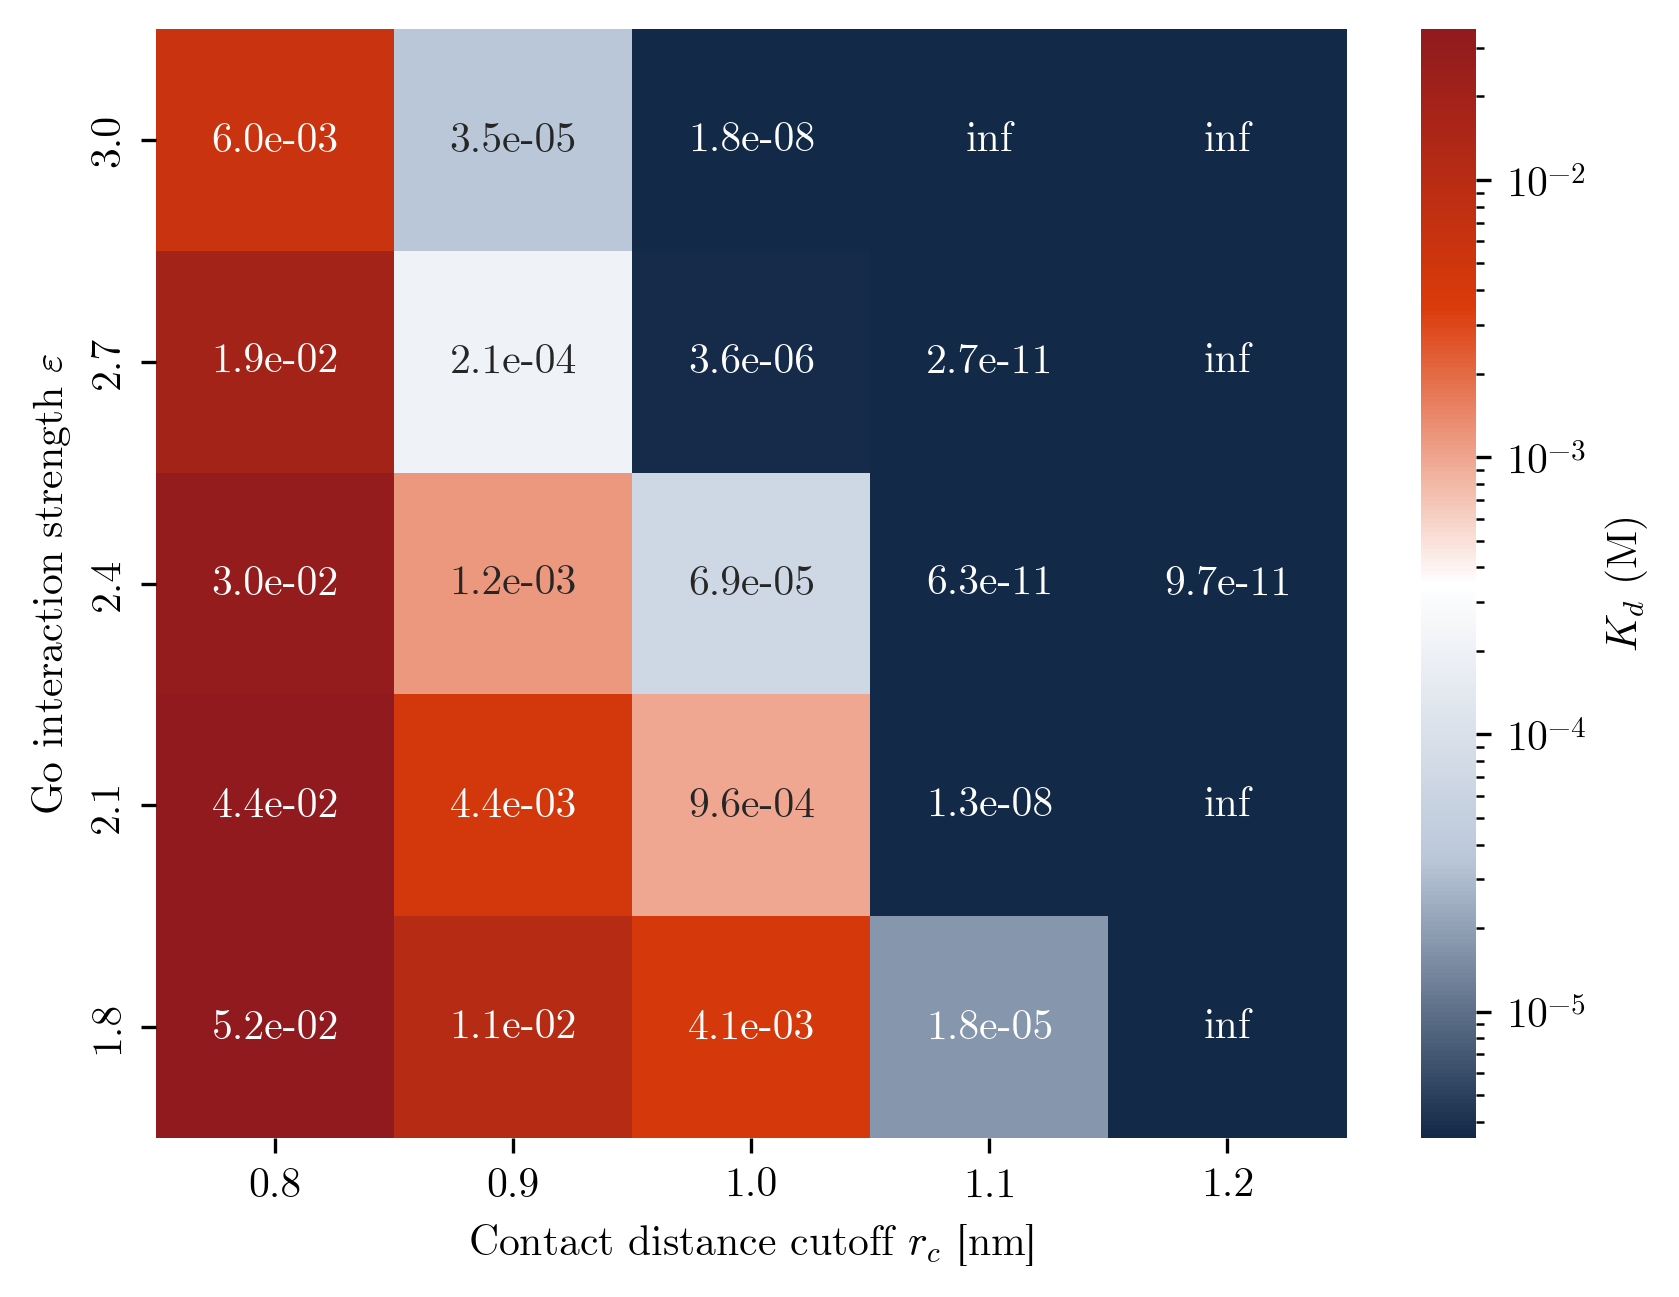

In [56]:
# Parameter landscape
import matplotlib.colors as colors

pivot_df = sims.sort_values(['epsilon', 'cutoff']).pivot(index='epsilon', columns='cutoff', values='Kd')[::-1] * 1e-6

midpoint = 350*1e-6
vmin = midpoint*1e-2
vmax = midpoint*1e2

norm = colors.LogNorm(vmin=vmin, vmax=vmax)

#plt.figure(figsize=(5, 5))
sns.heatmap(
    data=pivot_df.replace({np.inf: 1e-15}),
    norm=norm,
    cmap=vis.cmap.heat_cmap, 
    #center=midpoint, 
    annot=pivot_df,
    fmt=".1e",
    cbar_kws={'label': '$K_d$ (M)'}
)
plt.xlabel(r"Contact distance cutoff $r_c$ [nm]")
plt.ylabel(r"Go interaction strength $\varepsilon$")